# D1 · Photovoltaic plant: from the weather forecast to the energy bid (PySharp)

The same analysis as the [C#](D1-fotovoltaico-csharp.ipynb) notebook, with the `Interop` facade and `matplotlib`: **the same numbers**, verified by a test. `pysharp` kernel on .NET 11.

## The case

A **1 MWp photovoltaic plant** (600 kW AC inverter) sells energy on the day-ahead market. The SCADA records irradiance, temperatures, AC power and inverter state every hour; a weather service sends, the day before, the **irradiance forecast** for the next 24 hours, with its error.

**Who works on the data.** The *energy manager* must submit tomorrow's energy bid; whoever does *O&M* wants to know whether the plant performs as it should (and whether washing the modules is worth it); the *owner* wants to know why less was produced on a given day. The customer's question (the trader): **“how much energy do you offer on the market tomorrow?”**, and it must be given **with an uncertainty**, because producing less than offered costs more than producing more.

**Synthetic data** (`generate-data.cs`, with a seed): 8 hourly weeks. The first 7 for training, the last one as a never-seen test. The known truth is in `data/verita.json`: the cleaning of the modules (day 30), an inverter fault (day 38, 5 hours) and the weather service's error.

| Step | Question | Tool |
|---|---|---|
| 1 | Does the plant perform as it should? | KPIs: performance ratio, availability |
| 2 | How much power will it deliver tomorrow, **knowing the forecast weather**? | regression on the covariate, seasonal naive, MASE |
| 3 | With what uncertainty? | quantiles of the residuals by hour, pinball loss, coverage |
| 4 | And on the energy of the **whole day**? | sampled paths (blocks of residuals) |
| 5 | How much energy do I bid? | optimal quantile given the cost of the error |
| 6 | KPIs, dashboard, answer to the customer | tiles, charts, text with the numbers |

In [ ]:
import os, math, clr
import matplotlib.pyplot as plt

# The working directory must be inside the MathemaSharp repository (scripts/run-notebooks.ps1 starts from the root).
root = os.getcwd()
while not os.path.exists(os.path.join(root, "src", "MathemaSharp.slnx")):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError("Run the notebook with the working directory inside the MathemaSharp repository.")
    root = parent
clr.AddReference("D:/Dev/BuildArtifacts/MathemaSharp/bin/MathemaSharp.TimeSeries/release/MathemaSharp.TimeSeries.dll")
from MathemaSharp.TimeSeries.Interop import Statistics, Metrics, Linear

def P(label, values):
    if isinstance(values, (int, float)):
        values = [values]
    print(label + ": " + " ".join("%.6f" % v for v in values))

data = os.path.join(root, "scenari", "D-fotovoltaico", "data")
f = open(os.path.join(data, "impianto_orario.csv"))
text = f.read()
f.close()
rows = [l.split(",") for l in text.split(chr(10))[1:] if l.strip() != ""]
G = [float(r[1]) for r in rows]
Gf = [float(r[2]) for r in rows]
Tair = [float(r[3]) for r in rows]
Pac = [float(r[5]) for r in rows]
ok = [float(r[6]) for r in rows]
TRAIN_DAYS = 49
TRAIN_HOURS = TRAIN_DAYS * 24
TOTAL = 56 * 24
P_MAX = 600.0   # maximum AC kW of the inverter
P_NOM = 1000.0  # installed kWp

## 1 · Acquire and measure: does the plant perform as it should?
The **performance ratio** (IEC 61724) is the energy produced divided by what an ideal plant would produce with the same insolation: $PR=E_{AC}/(H_{POA}\cdot P_{nom})$. It measures the plant's health *regardless of the weather*. The **availability** counts the sunny hours in which the inverter was in service.

In [ ]:
daily_energy = [0.0] * 56
daily_insolation = [0.0] * 56
pr = [float("nan")] * 56
for d in range(56):
    for h in range(24):
        daily_energy[d] += Pac[d * 24 + h]
        daily_insolation[d] += G[d * 24 + h] / 1000
    if daily_insolation[d] > 0.5:
        pr[d] = daily_energy[d] / (daily_insolation[d] * P_NOM)

def mean_pr(first, last):
    values = [pr[d] for d in range(first, last)]
    return sum(values) / len(values)

P("pr_before_cleaning", mean_pr(24, 30))
P("pr_after_cleaning", mean_pr(31, 37))
P("pr_fault_day", pr[38])
sunny = [i for i in range(TOTAL) if G[i] > 50]
P("availability", sum([1 for i in sunny if ok[i] == 1]) / len(sunny))
P("hours_at_inverter_limit", sum([1 for p in Pac if p >= P_MAX - 0.05]))

pr_before_cleaning: 0.779849
pr_after_cleaning: 0.808781
pr_fault_day: 0.368400
availability: 0.992636
hours_at_inverter_limit: 17.000000


The PR rises after the cleaning of the modules (day 30) and drops on the day of the fault: the KPI sees both. But the difference due to cleaning is a few points: a **multi-day average** is needed to tell it from the noise.

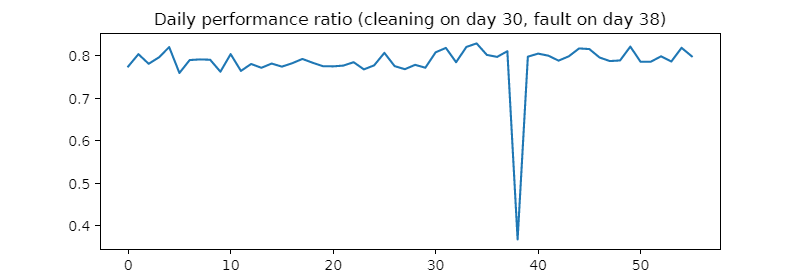

In [ ]:
plt.figure(figsize=(8, 2.8))
plt.plot(range(56), pr)
plt.title("Daily performance ratio (cleaning on day 30, fault on day 38)")
plt.show()

## 2 · Forecast tomorrow's power, knowing the forecast weather
Power depends on irradiance and a weather service forecasts it the day before: this is the **covariate known in the future** (with its error). Model: regression $P\approx\beta_0+\beta_1G_{prev}+\beta_2G_{prev}\,T_{air}$, limited to 0…600 kW, trained by QR on the hours when the inverter was in service. Reference: the **one-day seasonal naive** (the same hour as yesterday).

In [ ]:
train_rows = [i for i in range(TRAIN_HOURS) if ok[i] == 1]   # excluding the fault hours: they are not "normal"
flat = []
y = []
for i in train_rows:
    flat.extend([1.0, Gf[i], Gf[i] * Tair[i]])
    y.append(Pac[i])
beta = list(Linear.LeastSquares(flat, len(train_rows), 3, y))
P("beta", beta)

def predict(i):
    if Gf[i] <= 0:
        return 0.0
    return min(max(beta[0] + beta[1] * Gf[i] + beta[2] * Gf[i] * Tair[i], 0.0), P_MAX)

train = Pac[:TRAIN_HOURS]
test = Pac[TRAIN_HOURS:]
model = [predict(i) for i in range(TRAIN_HOURS, TRAIN_HOURS + 168)]
persistence = Pac[TRAIN_HOURS - 24:TOTAL - 24]   # yesterday at the same hour
P("mase_model", Metrics.Mase(test, model, train, 24))
P("mase_persistence", Metrics.Mase(test, persistence, train, 24))
try:
    Metrics.Mape(test, model)
    P("mape_defined", 1)
except ValueError:
    P("mape_defined", 0)   # at night the power is 0

beta: 10.992833 0.806969 -0.002707
mase_model: 0.510989
mase_persistence: 1.361532
mape_defined: 0.000000


**The MAPE cannot be computed**: at night the power is zero and the library says so instead of returning a meaningless number. This is why this book uses the **MASE**: defined even with zeros and scale-independent.

## 3 · With what uncertainty? Quantiles of the residuals by hour of the day
Forecasts err differently at every hour (at noon the error is large, at night nil). The model's **in-sample residuals** (actual − forecast power) are taken **hour by hour** and their quantiles computed: these are the offsets to add to the forecast to obtain P10, P50, P90.

In [ ]:
residual = [Pac[i] - predict(i) for i in range(TRAIN_HOURS)]

def hour_quantile(hour, p):
    return Statistics.Quantile([residual[i] for i in train_rows if i % 24 == hour], p)

q10 = [hour_quantile(h, 0.1) for h in range(24)]
q50 = [hour_quantile(h, 0.5) for h in range(24)]
q90 = [hour_quantile(h, 0.9) for h in range(24)]

def band(i, q):
    if Gf[i] <= 0:
        return 0.0
    return min(max(predict(i) + q[i % 24], 0.0), P_MAX)

lo = [band(i, q10) for i in range(TRAIN_HOURS, TOTAL)]
mid = [band(i, q50) for i in range(TRAIN_HOURS, TOTAL)]
hi = [band(i, q90) for i in range(TRAIN_HOURS, TOTAL)]
P("pinball_p10", Metrics.PinballLoss(test, lo, 0.1))
P("pinball_p50", Metrics.PinballLoss(test, mid, 0.5))
P("pinball_p90", Metrics.PinballLoss(test, hi, 0.9))
P("coverage_p10_p90_all_hours", Metrics.IntervalCoverage(test, lo, hi))
# At night the power is 0 and the interval is [0, 0]: it always contains the value and inflates the coverage. We measure only on the sunny hours.
daylight = [t for t in range(168) if Gf[TRAIN_HOURS + t] > 0]
coverage_day = Metrics.IntervalCoverage([test[t] for t in daylight], [lo[t] for t in daylight], [hi[t] for t in daylight])
P("coverage_p10_p90_sun_hours", coverage_day)

pinball_p10: 4.859385
pinball_p50: 11.591131
pinball_p90: 4.671934
coverage_p10_p90_all_hours: 0.916667
coverage_p10_p90_sun_hours: 0.846154


The P10–P90 interval should contain **80 %** of the observations. Counting **all** the hours the coverage looks high, but it is an illusion: at night the power is zero and the interval is [0, 0], so it always contains the value. Measured **on the sunny hours only** it is the number that counts; if it came out lower than 80 %, the interval would be too optimistic (the in-sample residuals underestimate the error on new data).

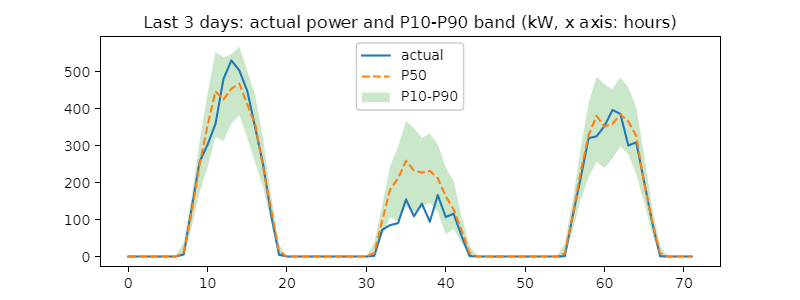

In [ ]:
a = 96
b = 168
plt.figure(figsize=(8, 3))
plt.plot(range(b - a), test[a:b], label="actual")
plt.plot(range(b - a), mid[a:b], linestyle="--", label="P50")
plt.fill_between(range(b - a), lo[a:b], hi[a:b], alpha=0.25, label="P10-P90")
plt.title("Last 3 days: actual power and P10-P90 band (kW, x axis: hours)")
plt.legend()
plt.show()

## 4 · And the energy of the **whole day**?
The trader's question concerns the kWh of the day, not the power of one hour. **Summing the hourly P10s does not give the day's P10**: it amounts to assuming that all 24 hours err together in the worst possible way. Instead, the **dependencies over time** are preserved by sampling paths: for each training day its entire residual vector is taken, added to the forecast, and one possible energy is obtained. From the 48 possible energies the quantiles are taken (fault day excluded).

In [ ]:
ok_days = [d for d in range(TRAIN_DAYS) if d != 38]
p10_day = []
p25_day = []
p50_day = []
p90_day = []
actual_day = []
sum_lo = []
sum_hi = []
for d in range(7):
    totals = []
    for k in ok_days:
        s = 0.0
        for h in range(24):
            i = TRAIN_HOURS + d * 24 + h
            if Gf[i] > 0:
                s += min(max(model[d * 24 + h] + residual[k * 24 + h], 0.0), P_MAX)
        totals.append(s)
    p10_day.append(Statistics.Quantile(totals, 0.1))
    p25_day.append(Statistics.Quantile(totals, 0.25))
    p50_day.append(Statistics.Quantile(totals, 0.5))
    p90_day.append(Statistics.Quantile(totals, 0.9))
    a_sum = 0.0
    lo_sum = 0.0
    hi_sum = 0.0
    for h in range(24):
        a_sum += test[d * 24 + h]
        lo_sum += lo[d * 24 + h]
        hi_sum += hi[d * 24 + h]
    actual_day.append(a_sum)
    sum_lo.append(lo_sum)
    sum_hi.append(hi_sum)
P("energy_actual", actual_day)
P("energy_p10", p10_day)
P("energy_p50", p50_day)
P("energy_p90", p90_day)
P("energy_sum_p10", sum_lo)
P("energy_sum_p90", sum_hi)

def inside(low, high):
    return sum([1 for d in range(7) if actual_day[d] >= low[d] and actual_day[d] <= high[d]])

P("days_within_paths", inside(p10_day, p90_day))
P("days_within_hourly_sum", inside(sum_lo, sum_hi))
P("paths_width_kwh", sum([p90_day[d] - p10_day[d] for d in range(7)]) / 7)
P("hourly_sum_width_kwh", sum([sum_hi[d] - sum_lo[d] for d in range(7)]) / 7)

energy_actual: 1414.800000 4036.600000 3908.600000 3150.400000 3721.700000 1192.200000 3001.100000
energy_p10: 914.216513 2432.517031 2803.159339 1480.914654 2835.150288 1195.885183 2308.782712
energy_p50: 1748.521896 3269.379526 3639.933614 2315.279025 3670.481569 2027.662215 3139.423999
energy_p90: 2443.001177 3963.858806 4334.412895 3009.758305 4364.960850 2722.141495 3833.903279
energy_sum_p10: 796.324391 2315.913303 2686.467392 1365.298881 2718.824564 1081.509182 2195.316611
energy_sum_p90: 2682.711908 4203.569537 4574.123626 3249.469036 4604.671581 2961.852226 4073.614010
days_within_paths: 4.000000
days_within_hourly_sum: 7.000000
paths_width_kwh: 1528.773012
hourly_sum_width_kwh: 1884.336800


The band **from the paths** is narrower than the one obtained by summing the hourly quantiles (about **1.5 MWh** against **1.9 MWh** on average): it takes into account how much the errors offset each other during the day, while the sum assumes the worst case on all the hours together, which is why it always contains all seven days. The days inside the paths band are **4 out of 7** against the expected 80 %: with only 7 days this is compatible with chance (seeing 4 or fewer out of 7 with probability 0.8 happens about 15 times in 100). **This is not a calibration**: many more test origins are needed.

## 5 · How much energy to bid? The quantile that costs least
On the market, **producing less than offered costs more** than producing more: if the shortfall costs $a$ per kWh and the excess $b$, the bid that minimises the expected cost is the **quantile of level $b/(a+b)$** of the energy distribution: this is the pinball loss of the chapter on probabilistic forecasts. With $a=3,\;b=1$ the level is **0.25**.

In [ ]:
def cost(offer, actual):
    return 3 * max(offer - actual, 0) + 1 * max(actual - offer, 0)   # a = 3 (shortfall), b = 1 (excess)

def week_cost(offers):
    return sum([cost(offers[d], actual_day[d]) for d in range(7)])

P("bid_cost_p10", week_cost(p10_day))
P("bid_cost_p25", week_cost(p25_day))
P("bid_cost_p50", week_cost(p50_day))
P("bid_cost_p90", week_cost(p90_day))
offers = [("p10", p10_day), ("p25", p25_day), ("p50", p50_day), ("p90", p90_day)]
best_offer = min(offers, key=lambda o: week_cost(o[1]))
print("best_bid: " + best_offer[0])

bid_cost_p10: 6469.515011
bid_cost_p25: 5093.702594
bid_cost_p50: 5844.750598
bid_cost_p90: 13593.441976
best_bid: p25


On the test week the 0.25 level costs less than bidding the median (P50) and much less than the P90, as the theory says. With seven days this is a confirmation, not a proof: the theory holds **on average**, and the cost of one week is noisy.

## 6 · Communicate: KPIs, dashboard and answer to the customer

In [ ]:
STATUS = {"ok": "&#10003; normal", "warn": "&#9650; warning", "alarm": "&#10006; alarm", "": ""}

def tiles(items):
    html = '<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:8px;font-family:system-ui,sans-serif">'
    for label, value, note, status in items:
        html += '<div style="background:#fcfcfb;border:1px solid #e4e3df;border-radius:8px;padding:10px 12px">'
        html += '<div style="font-size:12px;color:#52514e">' + label + '</div>'
        html += '<div style="font-size:26px;font-weight:600;color:#0b0b0b;line-height:1.2">' + value + '</div>'
        html += '<div style="font-size:12px;color:#52514e">' + note + '</div>'
        if STATUS[status] != "":
            html += '<div style="font-size:12px;font-weight:600;color:#0b0b0b;margin-top:2px">' + STATUS[status] + '</div>'
        html += '</div>'
    display_html(html + '</div>')

def quote(title, text):
    display_html('<div style="background:#fcfcfb;border-left:4px solid #2a78d6;padding:10px 14px;margin:8px 0;font-family:system-ui,sans-serif;color:#0b0b0b"><div style="font-size:12px;color:#52514e">' + title + '</div><div style="font-size:14px">' + text + '</div></div>')

last = 6
tiles([
    ("Performance ratio", "%.3f" % mean_pr(31, 37), "after cleaning, against %.3f before" % mean_pr(24, 30), "ok"),
    ("Availability", "%.1f %%" % (100.0 * sum([1 for i in sunny if ok[i] == 1]) / len(sunny)), "sunny hours with the inverter in service; 5 fault hours on day 38", "ok"),
    ("Energy tomorrow (P25)", "%.0f kWh" % p25_day[last], "P10 %.0f &ndash; P90 %.0f kWh; median %.0f" % (p10_day[last], p90_day[last], p50_day[last]), "ok"),
    ("P10&ndash;P90 coverage", "%.0f %%" % (100 * coverage_day), "sunny hours, on the test week (expected 80 %)", "warn" if coverage_day < 0.7 else "ok"),
    ("Model MASE", "%.2f" % Metrics.Mase(test, model, train, 24), "against %.2f for persistence (yesterday = today)" % Metrics.Mase(test, persistence, train, 24), "ok"),
])

Performance ratio 0.809 after cleaning, against 0.780 before ✓ normal Availability 99.3 % sunny hours with the inverter in service; 5 fault hours on day 38 ✓ normal Energy tomorrow (P25) 2768 kWh P10 2309 – P90 3834 kWh; median 3139 ✓ normal P10–P90 coverage 85 % sunny hours, on the test week (expected 80 %) ✓ normal Model MASE 0.51 against 1.36 for persistence (yesterday = today) ✓ normal

Answer to the customer: how much energy do you offer on the market tomorrow? For 20 September we offer 2768 kWh. This is the 25 % level of the expected energy distribution (median 3139 kWh, 10-90 % interval from 2309 to 3834 kWh): the market penalises a shortfall three times as much as an excess, and bidding the 25 %% level is what minimises the expected cost. The forecast is based on the irradiance forecast by the weather service: if the weather changes, we will update the bid before the market closes.

Note for O&M The mean performance ratio rose from 0.780 to 0.809 after the modules were cleaned on day 30: the dirt cost about 3.6 % of energy. On the fault day (38) the PR dropped to 0.37: 5 hours of inverter downtime.

In [ ]:
answer = ("For 20 September we offer %.0f kWh. This is the 25 %% level of the expected energy distribution (median %.0f kWh, 10-90 %% interval from %.0f to %.0f kWh): " % (p25_day[last], p50_day[last], p10_day[last], p90_day[last])
    + "the market penalises a shortfall three times as much as an excess, and bidding the 25 %% level is what minimises the expected cost. "
    + "The forecast is based on the irradiance forecast by the weather service: if the weather changes, we will update the bid before the market closes.")
quote("Answer to the customer: how much energy do you offer on the market tomorrow?", answer)

gain = 100 * (mean_pr(31, 37) - mean_pr(24, 30)) / mean_pr(31, 37)
oem = ("The mean performance ratio rose from %.3f to %.3f after the modules were cleaned on day 30: the dirt cost about %.1f %% of energy. " % (mean_pr(24, 30), mean_pr(31, 37), gain)
    + "On the fault day (38) the PR dropped to %.2f: 5 hours of inverter downtime." % pr[38])
quote("Note for O&M", oem)

## What we learned
- **The right KPI removes the weather**: the PR separates the plant's health from the weather.
- **A known covariate improves** the forecast a lot, but it brings its own error with it: the uncertainty of the weather forecast *is* the uncertainty of the bid.
- **No MAPE, yes MASE**: with the nightly zeros the MAPE does not exist.
- **Hourly quantiles do not add up**: for the day's energy, paths are sampled, preserving the dependencies over time.
- **The cost of the error decides the quantile**: bidding the median is not optimal when a shortfall costs more than an excess.
- **One test week is not enough** to calibrate the interval: validation on several origins (*rolling origin*) and conformal prediction are in the book, not yet in the library.